# EDA — dessins de construction Junction (preview)

Ce notebook explore l'aperçu du jeu de données du défi **Junction** : des dessins de construction (Europe et États-Unis, une trentaine de langues) accompagnés, pour une partie d'entre eux, de questions de **métré** (*quantity takeoff*).

Le corpus complet annoncé dans le README fait environ **14 000 dessins** et **120 000 questions**. Ici on n'a que le *preview* livré dans `junction-dataset-preview.zip`.

Chaque question a la forme :

```json
{"path": "data/swiss_dwellings/site3387_bldg5238_floor23498.pdf", "question": "How many apartments ...?", "answer": 2, "unit": "count", "type": "count"}
```

`type` vaut `count`, `area`, `length`, `volume`, `text` ou `other`. Au scoring : les comptages doivent être exacts, les aires / longueurs / volumes à 2 % près, les réponses texte sont libres.

Les fichiers de même nom et d'extension différente sont le même dessin dans un autre format. Les plans `ifc_models` du type `<model>_<niveau>.pdf` sont des rendus du modèle `<model>.ifc`.

## 1. Chargement

Le notebook retrouve le dossier extrait à côté de lui. S'il n'existe pas encore, il extrait le zip.

In [1]:
from pathlib import Path
import zipfile
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

try:
    import pymupdf as fitz
except ImportError:
    fitz = None

plt.rcParams.update({
    "figure.figsize": (10, 4.2),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.axisbelow": True,
    "font.size": 11,
    "figure.dpi": 110,
})

def locate_preview() -> Path:
    here = Path.cwd()
    candidates = [here, here / "stoa-preview", *here.parents, *(p / "stoa-preview" for p in here.parents)]
    candidates.append(Path(r"d:\Mes travaux\Hackaton Junction\junction\stoa-preview"))
    seen = set()
    for folder in candidates:
        folder = folder.resolve()
        if folder in seen or not folder.exists():
            continue
        seen.add(folder)
        root = folder / "junction-dataset-preview"
        if (root / "questions.jsonl").exists():
            return root
        zip_path = folder / "junction-dataset-preview.zip"
        if zip_path.exists():
            print(f"Extraction de {zip_path.name} ...")
            with zipfile.ZipFile(zip_path) as zf:
                zf.extractall(folder)
            return root
    raise FileNotFoundError("Preview introuvable. Place le zip à côté du notebook.")

ROOT = locate_preview()
DATA = ROOT / "data"
print("ROOT =", ROOT)
print("PyMuPDF :", "oui" if fitz else "non (les PDF ne seront pas rasterisés)")

ROOT = D:\Mes travaux\Hackaton Junction\junction\stoa-preview\junction-dataset-preview
PyMuPDF : oui


## 2. Inventaire des fichiers

Neuf sources, décrites dans le README :

| source | contenu |
|---|---|
| `cubicasa5k` | plans immobiliers finlandais (CubiCasa5K) |
| `swiss_dwellings` | étages d'appartements suisses, dérivés d'une géométrie publiée |
| `opening_design` | jeux de plans réels d'une agence d'architecture américaine |
| `ifc_models` | modèles IFC ouverts et plans rendus depuis ces modèles |
| `ifc_bench` | modèles IFC avec les questions IFC-Bench v2 |
| `habs` | relevés historiques américains (Library of Congress) |
| `finna` | archives d'Helsinki et musée d'architecture |
| `europeana` | dessins de musées et d'archives européens |
| `wikimedia` | plans issus de Wikimedia Commons |

Les licences restent fichier par fichier, dans `data/<source>/LICENSE.md`. CubiCasa est en CC BY-NC-SA 4.0 (usage non commercial).

913 dessins  |  9 fichiers LICENSE.md
Volume total : 725 Mo


ext,.dwg,.dxf,.ifc,.jpg,.pdf,.png,.svg,total
source,,,,,,,,
cubicasa5k,0,0,0,0,0,241,0,241
swiss_dwellings,0,65,0,0,65,65,0,195
wikimedia,0,0,0,125,0,0,7,132
finna,0,0,0,96,0,0,0,96
habs,0,0,0,92,0,0,0,92
opening_design,20,1,5,0,55,0,0,81
europeana,0,0,0,61,0,0,0,61
ifc_models,0,0,4,0,3,0,3,10
ifc_bench,0,0,5,0,0,0,0,5


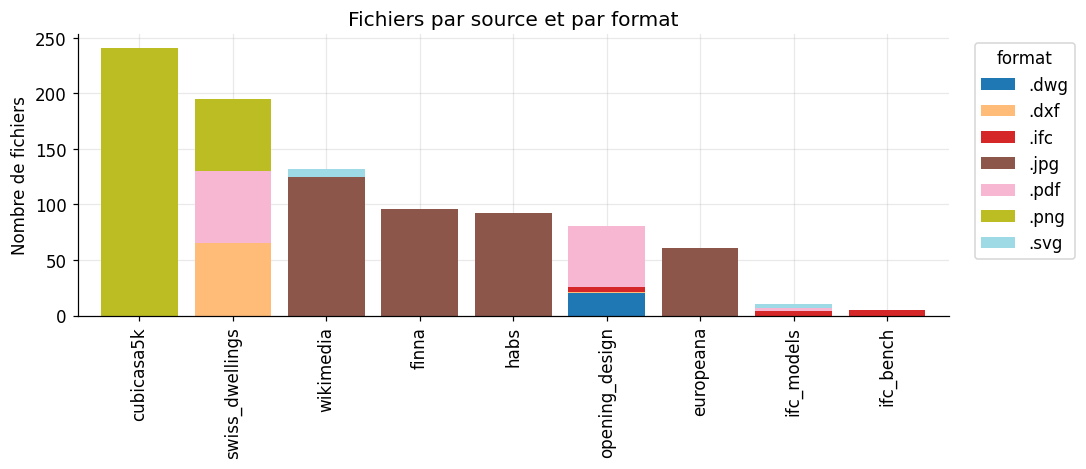

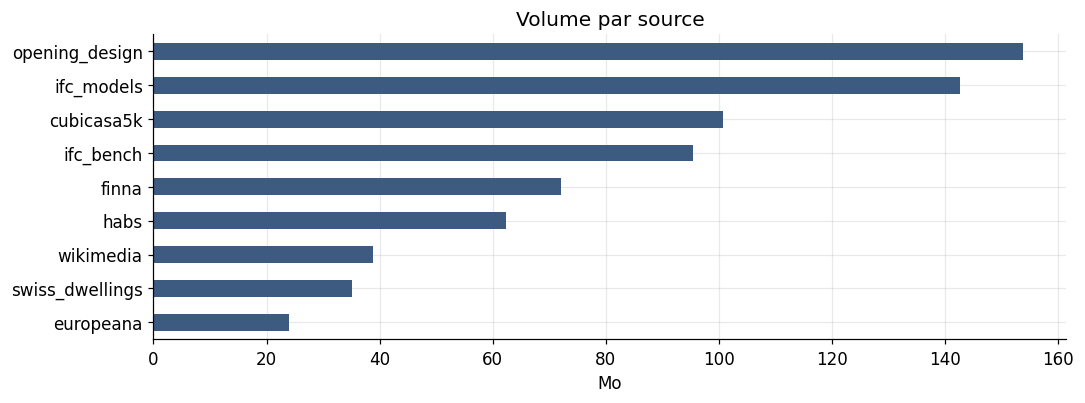

In [2]:
rows = []
for path in DATA.rglob("*"):
    if not path.is_file():
        continue
    rel = path.relative_to(DATA)
    source = rel.parts[0]
    ext = path.suffix.lower() or "(aucune)"
    rows.append({
        "source": source,
        "ext": ext,
        "bytes": path.stat().st_size,
        "rel": path.relative_to(ROOT).as_posix(),
        "name": path.name,
        "depth": len(rel.parts) - 1,
    })

files = pd.DataFrame(rows)
drawings = files[files["ext"] != ".md"].copy()

print(f"{len(drawings)} dessins  |  {files['ext'].eq('.md').sum()} fichiers LICENSE.md")
print(f"Volume total : {drawings['bytes'].sum() / 1e6:.0f} Mo")

counts = pd.crosstab(drawings["source"], drawings["ext"])
counts["total"] = counts.sum(axis=1)
counts = counts.sort_values("total", ascending=False)
display(counts)

order = counts.index.tolist()
ext_order = [c for c in counts.columns if c != "total"]
ax = counts[ext_order].plot(kind="bar", stacked=True, width=0.82, colormap="tab20", figsize=(10, 4.4))
ax.set_title("Fichiers par source et par format")
ax.set_xlabel("")
ax.set_ylabel("Nombre de fichiers")
ax.legend(title="format", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

size_mb = drawings.groupby("source")["bytes"].sum().reindex(order) / 1e6
fig, ax = plt.subplots(figsize=(10, 3.8))
size_mb.sort_values().plot(kind="barh", ax=ax, color="#3d5a80")
ax.set_xlabel("Mo")
ax.set_ylabel("")
ax.set_title("Volume par source")
plt.tight_layout()
plt.show()

In [3]:
print("Profondeur des chemins (opening_design garde l'arborescence d'origine de l'agence) :")
display(
    drawings.groupby("source")["depth"].agg(["min", "median", "max"])
    .round(1)
    .reindex(order)
)

cuba = drawings[drawings["source"] == "cubicasa5k"].copy()
cuba["style"] = cuba["name"].str.split("-").str[0]
print("Styles CubiCasa (préfixe du nom de fichier) :")
display(cuba["style"].value_counts().rename("fichiers").to_frame())

Profondeur des chemins (opening_design garde l'arborescence d'origine de l'agence) :


,min,median,max
source,,,
cubicasa5k,1,1.0,1
swiss_dwellings,1,1.0,1
wikimedia,1,1.0,1
finna,1,1.0,1
habs,1,1.0,1
opening_design,3,4.0,5
europeana,1,1.0,1
ifc_models,1,1.0,1
ifc_bench,1,1.0,1


Styles CubiCasa (préfixe du nom de fichier) :


,fichiers
style,
high_quality_architectural,187
high_quality,41
colorful,13


## 3. Voir les images

Les rasters (PNG, JPEG) couvrent CubiCasa, les rendus Swiss Dwellings, et les scans d'archives. Les trois styles CubiCasa sont montrés à part : `colorful` (pièces teintées), `high_quality` et `high_quality_architectural`.

Les images sont réduites pour l'affichage. Le plan suisse est un dessin propre, coté, avec les surfaces nettes déjà écrites. Les archives (HABS, Finna, Europeana, Wikimedia) sont des scans : plans, coupes, élévations, parfois très éloignés d'un plan d'appartement contemporain.

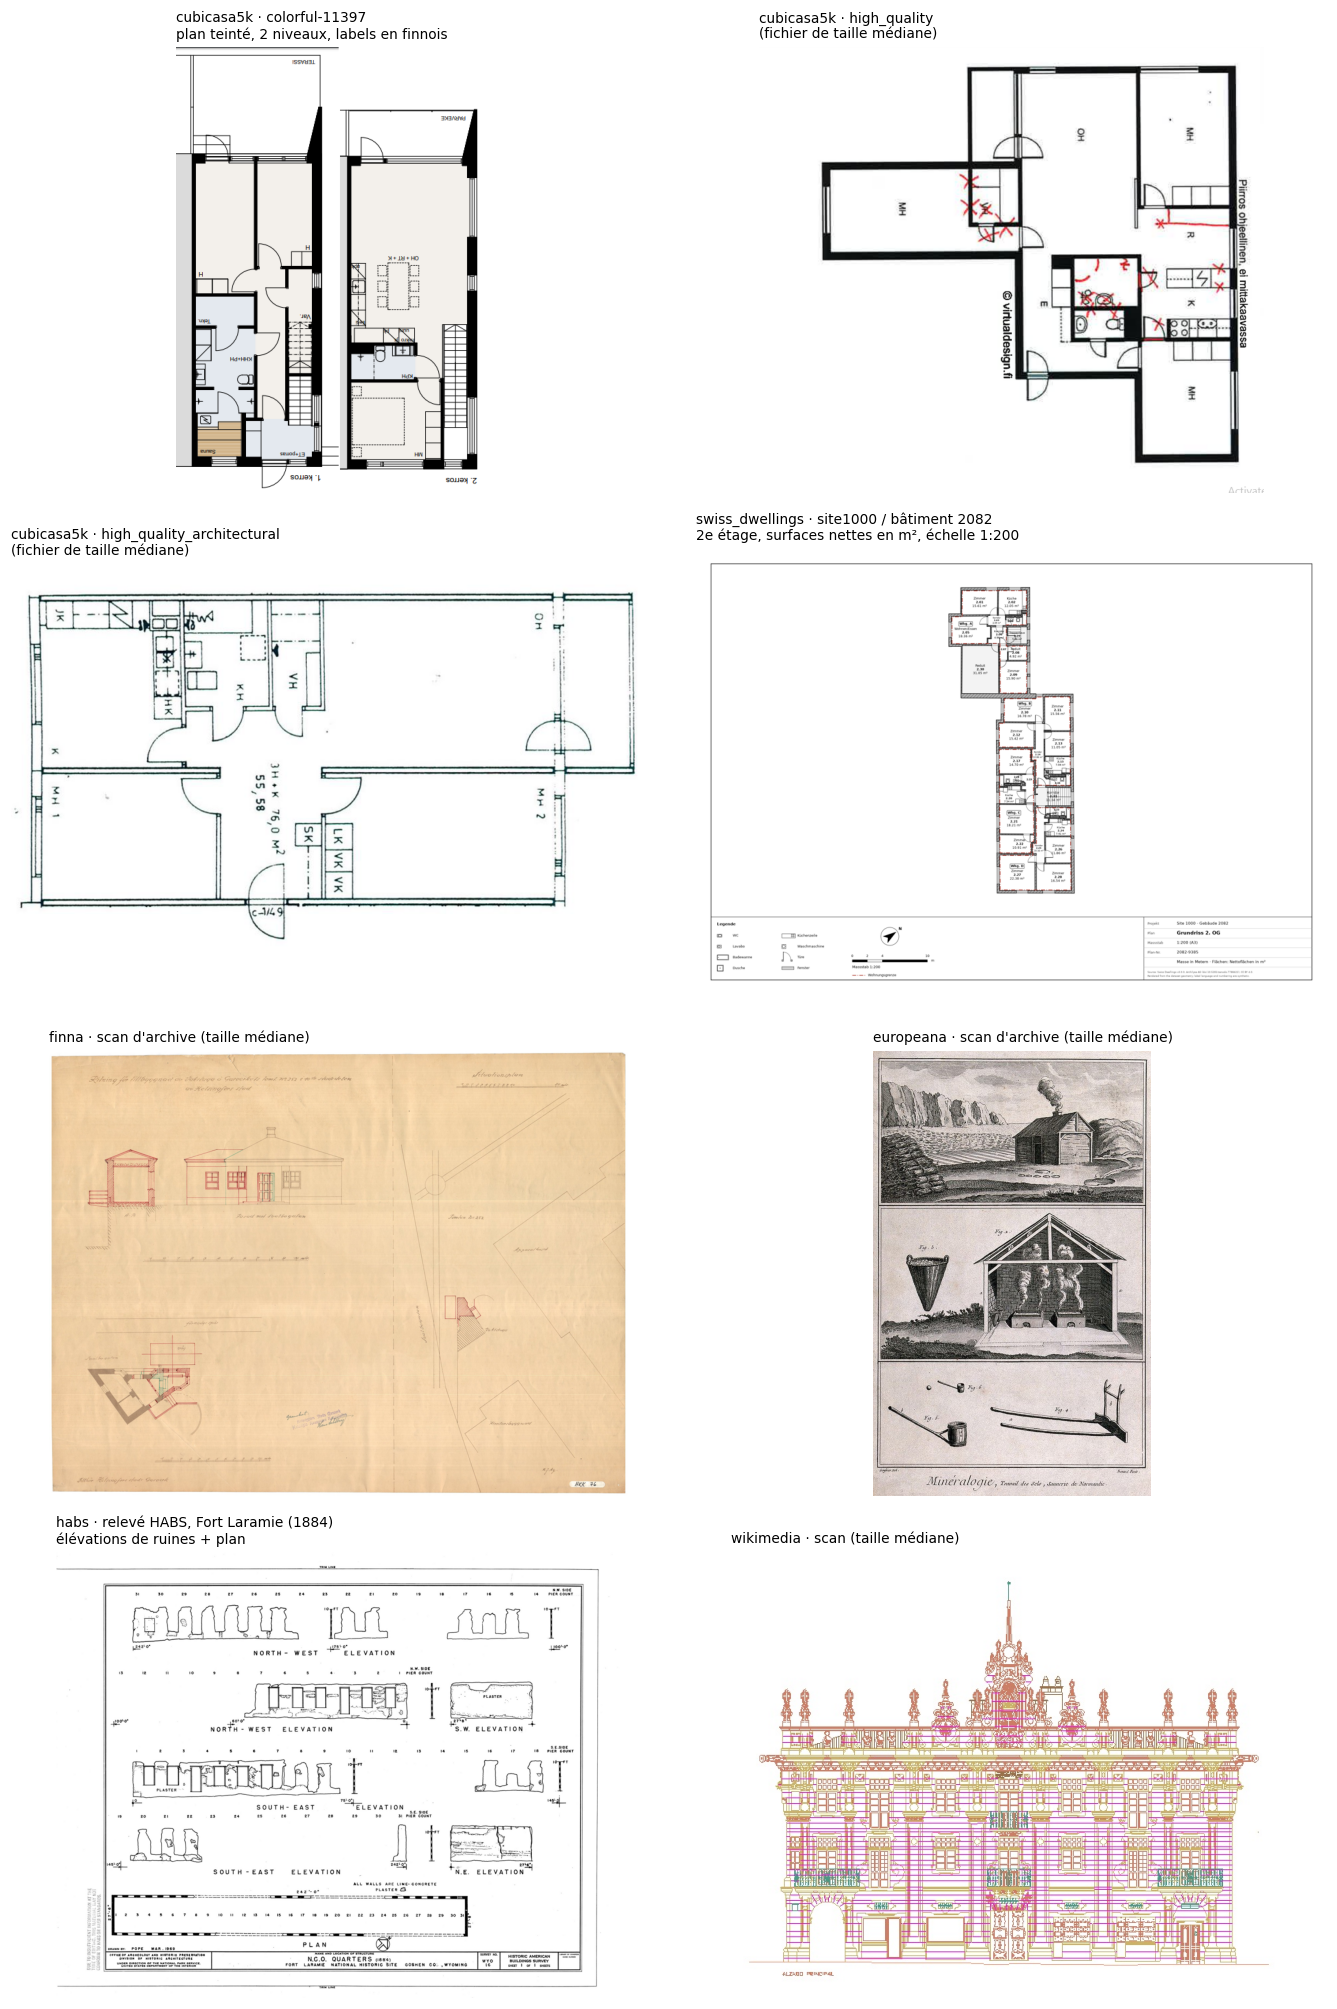

In [4]:
def thumb(path, max_side=980):
    with Image.open(path) as im:
        im = im.convert("RGB")
        im.thumbnail((max_side, max_side))
        return im.copy()

def show_images(items, ncols=2, title_size=9):
    """items : liste de (Path, titre)."""
    n = len(items)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 4.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (path, title) in zip(axes, items):
        ax.imshow(thumb(path))
        ax.set_title(title, fontsize=title_size, loc="left")
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def first_match(source, prefix=None, ext=".png"):
    subset = drawings[(drawings["source"] == source) & (drawings["ext"] == ext)]
    if prefix:
        subset = subset[subset["name"].str.startswith(prefix)]
    if subset.empty:
        return None
    # Fichier de taille médiane : ni une vignette, ni un scan géant.
    median = subset["bytes"].median()
    row = subset.iloc[(subset["bytes"] - median).abs().argsort().iloc[0]]
    return ROOT / row["rel"]

gallery = [
    (ROOT / "data/cubicasa5k/colorful-11397.png", "cubicasa5k · colorful-11397\nplan teinté, 2 niveaux, labels en finnois"),
    (first_match("cubicasa5k", "high_quality-"), "cubicasa5k · high_quality\n(fichier de taille médiane)"),
    (first_match("cubicasa5k", "high_quality_architectural-"), "cubicasa5k · high_quality_architectural\n(fichier de taille médiane)"),
    (ROOT / "data/swiss_dwellings/site1000_bldg2082_floor9385.png", "swiss_dwellings · site1000 / bâtiment 2082\n2e étage, surfaces nettes en m², échelle 1:200"),
    (first_match("finna", ext=".jpg"), "finna · scan d'archive (taille médiane)"),
    (first_match("europeana", ext=".jpg"), "europeana · scan d'archive (taille médiane)"),
    (ROOT / "data/habs/wy0044_sheet_00001.jpg", "habs · relevé HABS, Fort Laramie (1884)\nélévations de ruines + plan"),
    (first_match("wikimedia", ext=".jpg"), "wikimedia · scan (taille médiane)"),
]
gallery = [(p, t) for p, t in gallery if p is not None and p.exists()]
show_images(gallery, ncols=2)

680 images raster
Modes : {'RGB': 574, 'RGBA': 95, 'L': 11}


width               height                mpix              
                  min  median   max    min  median   max   min median    max
source                                                                      
cubicasa5k        200   808.0  4500    161   678.0  3621  0.04   0.53  12.00
europeana         373  1200.0  3000    289   980.0  3000  0.23   1.14   8.72
finna            1405  3000.0  3000    617  2252.0  3000  1.85   6.42   8.98
habs             1996  3000.0  3000   1768  2000.0  3000  5.30   6.00   7.32
swiss_dwellings  1753  2480.0  2480   1753  1753.0  2480  4.35   4.35   4.35
wikimedia         125  1136.0  2500     90   948.0  2500  0.01   1.05   6.25

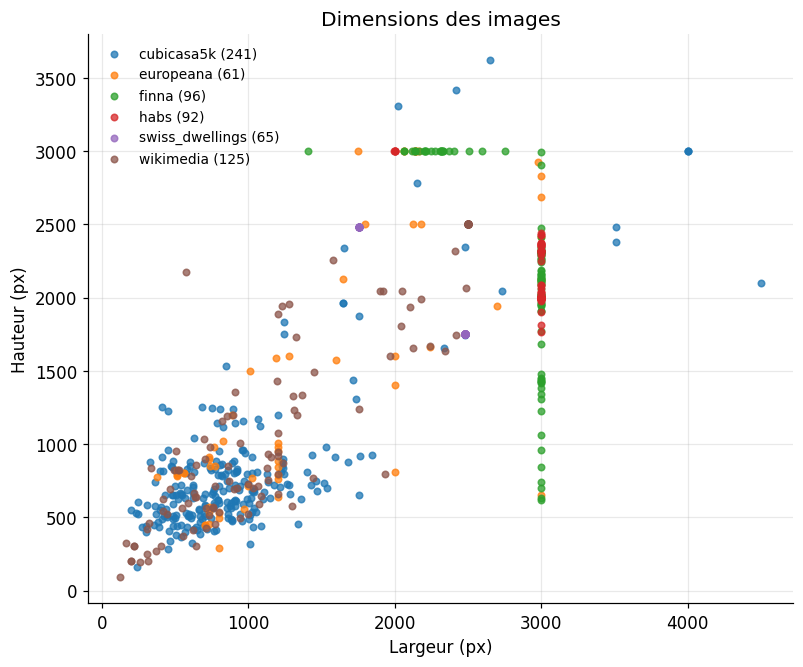

In [5]:
rasters = drawings[drawings["ext"].isin([".png", ".jpg", ".jpeg"])].copy()
widths, heights, modes = [], [], []
for rel in rasters["rel"]:
    with Image.open(ROOT / rel) as im:
        w, h = im.size
        widths.append(w)
        heights.append(h)
        modes.append(im.mode)

rasters["width"] = widths
rasters["height"] = heights
rasters["mode"] = modes
rasters["mpix"] = rasters["width"] * rasters["height"] / 1e6
rasters["ratio"] = rasters["width"] / rasters["height"]

print(f"{len(rasters)} images raster")
print("Modes :", rasters["mode"].value_counts().to_dict())
display(
    rasters.groupby("source")[["width", "height", "mpix"]]
    .agg(["min", "median", "max"])
    .round(2)
)

fig, ax = plt.subplots(figsize=(8.2, 6.2))
for source, part in rasters.groupby("source"):
    ax.scatter(part["width"], part["height"], s=18, alpha=0.75, label=f"{source} ({len(part)})")
ax.set_xlabel("Largeur (px)")
ax.set_ylabel("Hauteur (px)")
ax.set_title("Dimensions des images")
ax.legend(frameon=False, fontsize=9)
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

## 4. PDF, et les formats qu'on ne peut pas « voir » comme une photo

123 PDF, 66 DXF, 20 DWG, 14 IFC, 10 SVG. Les questions de Swiss Dwellings et d'Opening Design pointent souvent vers le PDF, pas vers le PNG. Les gros volumes sont les IFC (modèles BIM, jusqu'à plusieurs dizaines de Mo).

123 PDF, 185 pages au total


,count,min,median,max,sum
source,,,,,
ifc_models,3,1,1.0,1,3
opening_design,55,1,1.0,15,117
swiss_dwellings,65,1,1.0,1,65


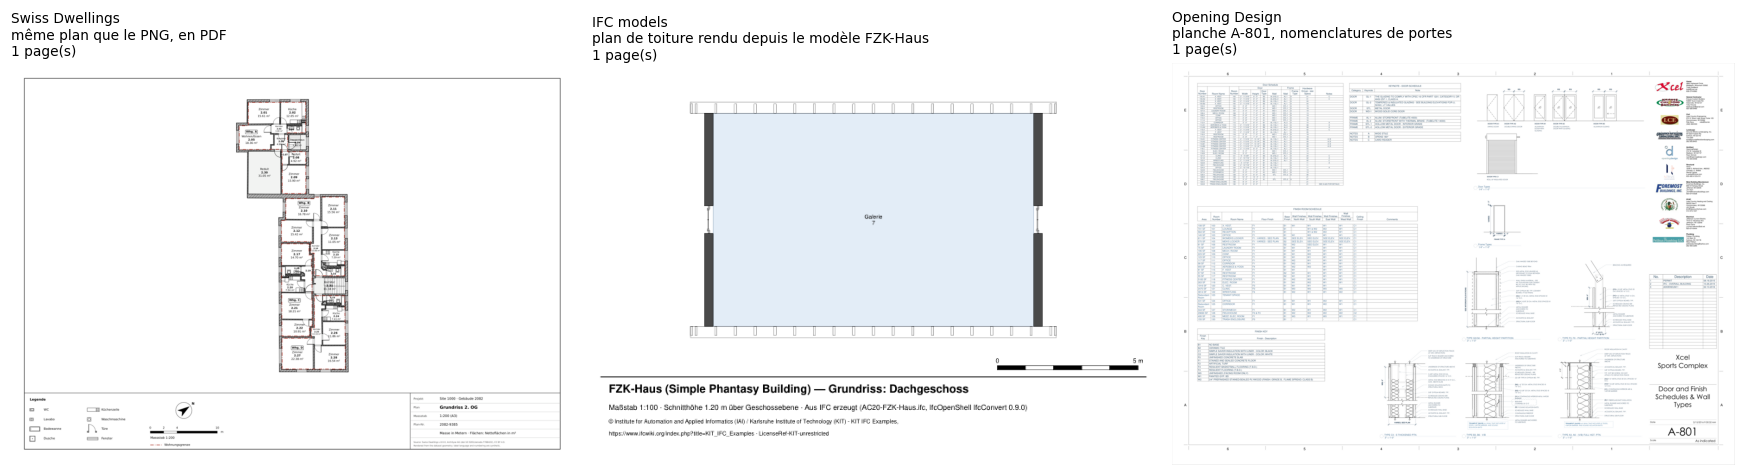

In [6]:
pdfs = drawings[drawings["ext"] == ".pdf"].copy()

if fitz is None:
    print("PyMuPDF absent : pas de rendu PDF. Les chemins sont quand même listés.")
    display(pdfs.groupby("source").size().rename("pdf").to_frame())
else:
    pages, page_w, page_h = [], [], []
    for rel in pdfs["rel"]:
        doc = fitz.open(ROOT / rel)
        pages.append(doc.page_count)
        box = doc[0].rect
        page_w.append(box.width)
        page_h.append(box.height)
        doc.close()
    pdfs["pages"] = pages
    pdfs["page_w_pt"] = page_w
    pdfs["page_h_pt"] = page_h
    print(f"{len(pdfs)} PDF, {pdfs['pages'].sum()} pages au total")
    display(pdfs.groupby("source")["pages"].agg(["count", "min", "median", "max", "sum"]).round(1))

    def render_pdf(rel, zoom=1.15):
        doc = fitz.open(ROOT / rel)
        page = doc[0]
        pix = page.get_pixmap(matrix=fitz.Matrix(zoom, zoom), alpha=False)
        im = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
        doc.close()
        im.thumbnail((1100, 1100))
        return im

    samples = [
        "data/swiss_dwellings/site1000_bldg2082_floor9385.pdf",
        "data/ifc_models/kit-fzk-haus_ac20-fzk-haus_plan-02-dachgeschoss.pdf",
        "data/opening_design/Sports_Complex/Sheets - Current Set/A-801 - Door and Finish Schedules & Wall Types.pdf",
    ]
    fig, axes = plt.subplots(1, 3, figsize=(16, 7.2))
    titles = [
        "Swiss Dwellings\nmême plan que le PNG, en PDF",
        "IFC models\nplan de toiture rendu depuis le modèle FZK-Haus",
        "Opening Design\nplanche A-801, nomenclatures de portes",
    ]
    for ax, rel, title in zip(axes, samples, titles):
        try:
            ax.imshow(render_pdf(rel))
            n = int(pdfs.loc[pdfs["rel"] == rel, "pages"].iloc[0])
            ax.set_title(f"{title}\n{n} page(s)", fontsize=9, loc="left")
        except Exception as exc:
            ax.text(0.5, 0.5, f"rendu impossible\n{exc}", ha="center", va="center")
            ax.set_title(rel, fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [7]:
def sniff(rel, nbytes=500):
    raw = (ROOT / rel).read_bytes()[:nbytes]
    text = raw.decode("utf-8", errors="replace")
    print(f"\n----- {rel} -----")
    print(text[:nbytes])

# Le plus petit IFC du preview, puis un DXF suisse : les deux sont du texte, pas des pixels.
ifc_small = drawings[drawings["ext"] == ".ifc"].sort_values("bytes").iloc[0]
dxf_one = drawings[(drawings["source"] == "swiss_dwellings") & (drawings["ext"] == ".dxf")].iloc[0]
print("IFC du preview, du plus léger au plus lourd :")
display(
    drawings[drawings["ext"] == ".ifc"][["rel", "bytes"]]
    .assign(Mo=lambda d: (d["bytes"] / 1e6).round(2))
    .drop(columns="bytes")
    .reset_index(drop=True)
)
sniff(ifc_small["rel"])
sniff(dxf_one["rel"])

# Même dessin, plusieurs formats.
stem_key = drawings["rel"].map(lambda p: str(Path(p).with_suffix("")).lower())
multi = drawings.groupby(stem_key)["ext"].agg(lambda s: tuple(sorted(set(s))))
multi = multi[multi.map(len) > 1]
print(f"\n{len(multi)} dessins existent en plusieurs formats")
print(multi.map(lambda t: " + ".join(t)).value_counts().to_string())

IFC du preview, du plus léger au plus lourd :


,rel,Mo
0,data/ifc_bench/ac20_arc.ifc,10.93
1,data/ifc_bench/digital_hub_arc.ifc,9.02
2,data/ifc_bench/duplex_arc.ifc,1.66
3,data/ifc_bench/fantasy_office_building_3_arc.ifc,9.66
4,data/ifc_bench/hitos_arc.ifc,64.10
5,data/ifc_models/bsc-clinic_clinic-plumbing.ifc,55.83
6,data/ifc_models/bsc-esplanades_1807-ep-ar-v18.ifc,12.11
7,data/ifc_models/bsc-molio_molio-with-uris.ifc,73.95
8,data/ifc_models/resbim-388_model.ifc,0.00
9,data/opening_design/ULI-44_E_Mifflin-Suite_802...,1.04



----- data/ifc_models/resbim-388_model.ifc -----
ISO-10303-21;
HEADER;
FILE_DESCRIPTION(('ViewDefinition [CoordinationView_V2.0]','RevitIdentifiers [ContentGUID: 09b8a7ad-8c9f-40c7-a980-c35bcfb0571b, VersionGUID: c22544dc-59af-4e4b-814f-f04db0b0c9fb, NumberOfSaves: 507]'),'2;1');
FILE_NAME('388.ifc','2026-04-15T17:47:10+01:00',(''),(''),'ODA SDAI 25.12','Autodesk - Revit 26.4.0.32 (ENG) - 26.4.0.32','');
FILE_SCHEMA(('IFC4'));
ENDSEC;

DATA;
#1=IFCORGANIZATION($,'Autodesk Revit 2026 (ENG)',$,$,$);
#2=IFCAPPLICATION(#1,'2026','Autodesk Revit 20

----- data/swiss_dwellings/site1000_bldg2082_floor9385.dxf -----
  0
SECTION
  2
HEADER
  9
$ACADVER
  1
AC1027
  9
$ACADMAINTVER
 70
105
  9
$DWGCODEPAGE
  3
ANSI_1252
  9
$LASTSAVEDBY
  1
ezdxf
  9
$REQUIREDVERSIONS
160
0
  9
$INSBASE
 10
0.0
 20
0.0
 30
0.0
  9
$EXTMIN
 10
1e+20
 20
1e+20
 30
1e+20
  9
$EXTMAX
 10
-1e+20
 20
-1e+20
 30
-1e+20
  9
$LIMMIN
 10
0.0
 20
0.0
  9
$LIMMAX
 10
420.0
 20
297.0
  9
$ORTHOMODE
 70
0
  9
$REGENMODE
 70


## 5. Les questions

`questions.jsonl` : une question par ligne, cinq champs (`path`, `question`, `answer`, `unit`, `type`). Dans ce preview, seules cinq sources ont des questions. Finna, Europeana, HABS et Wikimedia sont là comme dessins, sans question associée.

In [8]:
questions = pd.read_json(ROOT / "questions.jsonl", lines=True)
questions["source"] = questions["path"].str.split("/").str[1]
questions["ext"] = questions["path"].str.extract(r"(\.[A-Za-z0-9]+)$", expand=False).str.lower()
questions["q_len"] = questions["question"].str.len()
questions["answer_type"] = questions["answer"].map(lambda v: type(v).__name__)

print(f"{len(questions)} questions sur {questions['path'].nunique()} fichiers")
print("Colonnes :", list(questions.columns[:5]))
print("Chemins de questions absents du disque :", (~questions["path"].map(lambda p: (ROOT / p).exists())).sum())

display(questions.head(8))

asked = set(questions["path"])
coverage = (
    drawings.assign(avec_question=lambda d: d["rel"].isin(asked))
    .groupby("source")["avec_question"]
    .agg(fichiers="size", avec_question="sum")
)
coverage["sans_question"] = coverage["fichiers"] - coverage["avec_question"]
coverage["part_avec_question"] = (coverage["avec_question"] / coverage["fichiers"]).round(2)
display(coverage.reindex(order))
print(
    "Pour swiss_dwellings, les 130 fichiers sans question sont les PNG et les DXF "
    "jumeaux des 65 PDF interrogés : chaque étage a bien des questions, mais une seule fois."
)

7990 questions sur 320 fichiers
Colonnes : ['path', 'question', 'answer', 'unit', 'type']


Chemins de questions absents du disque : 0


,path,question,answer,unit,type,source,ext,q_len,answer_type
0,data/cubicasa5k/colorful-11397.png,How many windows are shown on this floor plan?,13,count,count,cubicasa5k,.png,46,int
1,data/cubicasa5k/colorful-11397.png,Kuinka monta ikkunaa pohjapiirustuksessa on?,13,count,count,cubicasa5k,.png,44,int
2,data/cubicasa5k/colorful-11397.png,How many toilet bowls (WC seats) are drawn on ...,2,count,count,cubicasa5k,.png,62,int
3,data/cubicasa5k/colorful-11397.png,Kuinka monta WC-istuinta pohjapiirustukseen on...,2,count,count,cubicasa5k,.png,57,int
4,data/cubicasa5k/colorful-11397.png,How many sinks and wash basins (kitchen and ba...,3,count,count,cubicasa5k,.png,126,int
5,data/cubicasa5k/colorful-11397.png,Kuinka monta pesu- ja tiskiallasta (keittiö ja...,3,count,count,cubicasa5k,.png,132,int
6,data/cubicasa5k/colorful-11397.png,How many showers and bathtubs are drawn on thi...,3,count,count,cubicasa5k,.png,68,int
7,data/cubicasa5k/colorful-11397.png,Kuinka monta suihkua ja kylpyammetta pohjapiir...,3,count,count,cubicasa5k,.png,78,int


,fichiers,avec_question,sans_question,part_avec_question
source,,,,
cubicasa5k,241,241,0,1.00
swiss_dwellings,195,65,130,0.33
wikimedia,132,0,132,0.00
finna,96,0,96,0.00
habs,92,0,92,0.00
opening_design,81,3,78,0.04
europeana,61,0,61,0.00
ifc_models,10,6,4,0.60
ifc_bench,5,5,0,1.00


Pour swiss_dwellings, les 130 fichiers sans question sont les PNG et les DXF jumeaux des 65 PDF interrogés : chaque étage a bien des questions, mais une seule fois.


Type de question :


,questions
type,
count,6076
area,1599
text,265
volume,34
length,16


Unité :


,questions
unit,
count,6076
m2,1590
None,265
m3,34
m,16
ft2,9


Type Python de la réponse :


,questions
answer_type,
int,6085
float,1640
str,265


type,area,count,length,text,volume,total
source,,,,,,
cubicasa5k,0,4270,0,0,0,4270
swiss_dwellings,744,1614,0,0,0,2358
ifc_models,846,153,16,0,34,1049
ifc_bench,0,0,0,249,0,249
opening_design,9,39,0,16,0,64


Extension du fichier visé par la question (le PNG suisse existe, mais la question pointe vers le PDF) :

ext,.ifc,.pdf,.png
source,,,
cubicasa5k,0,0,4270
ifc_bench,249,0,0
ifc_models,827,222,0
opening_design,0,64,0
swiss_dwellings,0,2358,0


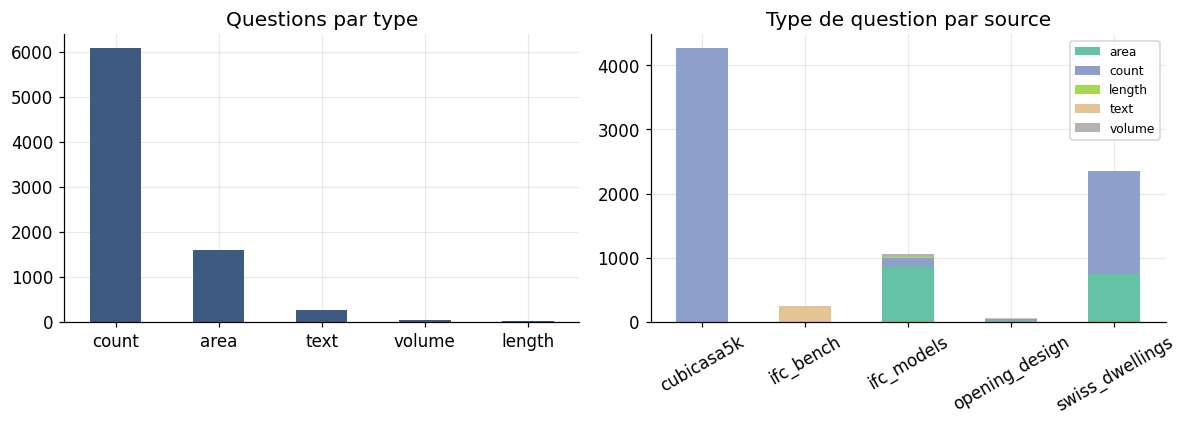

In [9]:
print("Type de question :")
display(questions["type"].value_counts().rename("questions").to_frame())
print("Unité :")
display(questions["unit"].value_counts(dropna=False).rename("questions").to_frame())
print("Type Python de la réponse :")
display(questions["answer_type"].value_counts().rename("questions").to_frame())

by_source = pd.crosstab(questions["source"], questions["type"])
by_source["total"] = by_source.sum(axis=1)
display(by_source.sort_values("total", ascending=False))

ext_by_source = pd.crosstab(questions["source"], questions["ext"])
print("Extension du fichier visé par la question (le PNG suisse existe, mais la question pointe vers le PDF) :")
display(ext_by_source)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
questions["type"].value_counts().plot(kind="bar", ax=axes[0], color="#3d5a80")
axes[0].set_title("Questions par type")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)
by_source.drop(columns="total").plot(kind="bar", stacked=True, ax=axes[1], colormap="Set2")
axes[1].set_title("Type de question par source")
axes[1].set_xlabel("")
axes[1].legend(title="", fontsize=8)
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 6. La même question, deux fois

Dans `questions.jsonl`, les lignes se suivent par paires. Une question en anglais ouvre le groupe, et la ligne suivante — même fichier, même réponse — en est la traduction : finnois pour CubiCasa, allemand pour Swiss Dwellings, estonien pour une partie des plans IFC. Deux questions différentes qui tombent sur la même réponse (2 WC et 2 étages, par exemple) ne doivent pas être fusionnées.

Le détecteur de langue ne regarde que le début de la phrase. Il est indicatif : l'estonien (`Mitu…`) est reconnu à part, et les tournures non prévues tombent dans « autre ».

In [10]:
def guess_lang(text: str) -> str:
    t = " ".join(str(text).lower().split())
    rules = [
        ("fi", ("kuinka ", "montako ", "mikä ", "mitkä ", "onko ")),
        ("de", ("wie ", "welche ", "welcher ", "welches ", "was ", "gibt es", "ist die ", "ist der ")),
        ("it", ("qual è", "qual'è", "quanti ", "quante ", "quanto ")),
        ("fr", ("combien ", "quelle ", "quelles ", "quel ", "quels ")),
        ("es", ("cuánt", "cuál ", "cuantos ", "cuantas ")),
        ("sv", ("hur ", "vilka ", "vilken ", "vad ")),
        ("nl", ("hoeveel ", "hoe ", "welke ")),
        ("pl", ("ile ", "jaka ", "jakie ", "czy ")),
        ("et", ("mitu ",)),
        ("en", ("how ", "what ", "which ", "list ", "give ", "is ", "are ", "could ", "can ", "on ", "calculate ", "find ", "where ", "name ", "describe ", "does ", "do ")),
    ]
    for code, prefixes in rules:
        if t.startswith(prefixes):
            return code
    return "autre"

questions["lang"] = questions["question"].map(guess_lang)
print("Langue estimée d'après le début de la question :")
display(questions["lang"].value_counts().rename("questions").to_frame())

# Une question anglaise ouvre un fait. La ligne suivante reste dans ce fait
# seulement si le fichier et la réponse sont les mêmes (c'est la traduction).
keys = list(zip(
    questions["path"],
    questions["type"],
    questions["unit"].astype(str),
    questions["answer"].map(lambda v: json.dumps(v, ensure_ascii=False)),
))
fact_ids = []
fact_id = -1
open_key = None
for lang, key in zip(questions["lang"], keys):
    if lang == "en" or key != open_key:
        fact_id += 1
        open_key = key
    fact_ids.append(fact_id)
questions["fact_id"] = fact_ids
wordings = questions.groupby("fact_id").size()
print(f"{questions['fact_id'].nunique()} questions distinctes pour {len(questions)} lignes")
print("Formulations par question (1 = une seule langue, 2 = original + traduction) :")
display(wordings.value_counts().sort_index().rename("questions").to_frame().rename_axis("formulations"))

print("\nExemple CubiCasa — colorful-11397, toutes les formulations :")
sample = questions[questions["path"] == "data/cubicasa5k/colorful-11397.png"][
    ["lang", "type", "question", "answer", "unit"]
].sort_values(["answer", "lang"])
display(sample.reset_index(drop=True))

Langue estimée d'après le début de la question :


,questions
lang,
en,4152
fi,2135
autre,487
de,422
fr,395
it,374
et,25


4152 questions distinctes pour 7990 lignes
Formulations par question (1 = une seule langue, 2 = original + traduction) :


,questions
formulations,
1,314
2,3838



Exemple CubiCasa — colorful-11397, toutes les formulations :


,lang,type,question,answer,unit
0,en,count,How many toilet bowls (WC seats) are drawn on ...,2,count
1,en,count,How many floors (storeys) does this floor plan...,2,count
2,fi,count,Kuinka monta WC-istuinta pohjapiirustukseen on...,2,count
3,fi,count,Kuinka monta kerrosta pohjapiirustuksessa on e...,2,count
4,en,count,How many sinks and wash basins (kitchen and ba...,3,count
5,en,count,How many showers and bathtubs are drawn on thi...,3,count
6,fi,count,Kuinka monta pesu- ja tiskiallasta (keittiö ja...,3,count
7,fi,count,Kuinka monta suihkua ja kylpyammetta pohjapiir...,3,count
8,en,count,How many windows are shown on this floor plan?,13,count
9,fi,count,Kuinka monta ikkunaa pohjapiirustuksessa on?,13,count


Formulations les plus fréquentes (le texte exact revient d'un plan à l'autre) :


,occurrences
question,
How many windows are shown on this floor plan?,241
Kuinka monta ikkunaa pohjapiirustuksessa on?,241
Kuinka monta kerrosta pohjapiirustuksessa on esitetty?,241
How many floors (storeys) does this floor plan show?,241
How many toilet bowls (WC seats) are drawn on this floor plan?,240
Kuinka monta WC-istuinta pohjapiirustukseen on piirretty?,240
How many sinks and wash basins (kitchen and bathroom combined; a double-bowl sink counts as one) are drawn on this floor plan?,239
Kuinka monta pesu- ja tiskiallasta (keittiö ja kylpytilat yhteensä; kaksoisallas lasketaan yhdeksi) pohjapiirustukseen on piirretty?,239
Kuinka monta suihkua ja kylpyammetta pohjapiirustukseen on piirretty yhteensä?,227


Questions par fichier :
count    320.0
mean      25.0
std       33.5
min        1.0
25%       16.0
50%       20.0
75%       24.0
max      486.0
Fichier le plus interrogé : data/ifc_models/bsc-esplanades_1807-ep-ar-v18.ifc → 486 questions


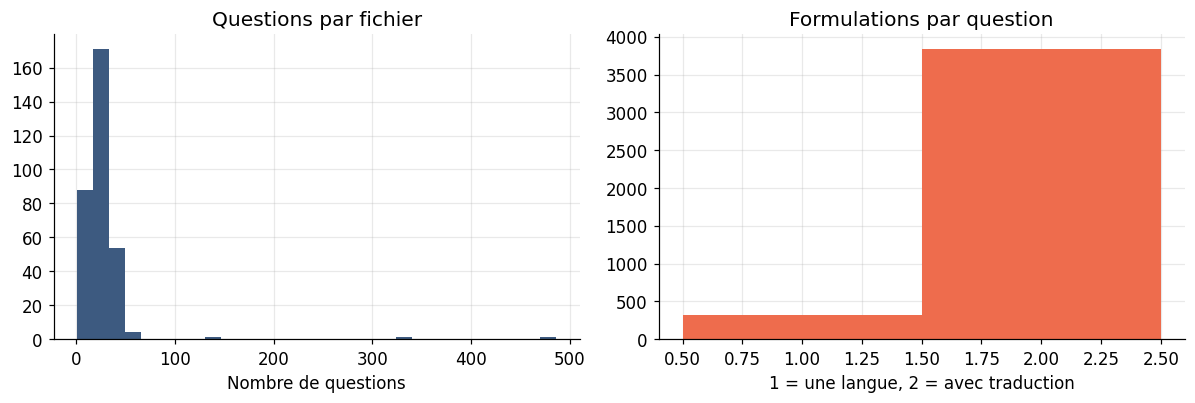

In [11]:
print("Formulations les plus fréquentes (le texte exact revient d'un plan à l'autre) :")
display(
    questions["question"].value_counts().head(15).rename("occurrences").to_frame()
)

per_file = questions.groupby("path").size()
print("Questions par fichier :")
print(per_file.describe().round(1).to_string())
print("Fichier le plus interrogé :", per_file.idxmax(), "→", int(per_file.max()), "questions")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(per_file, bins=30, color="#3d5a80")
axes[0].set_title("Questions par fichier")
axes[0].set_xlabel("Nombre de questions")
axes[1].hist(wordings, bins=np.arange(0.5, wordings.max() + 1.5, 1), color="#ee6c4d")
axes[1].set_title("Formulations par question")
axes[1].set_xlabel("1 = une langue, 2 = avec traduction")
plt.tight_layout()
plt.show()

## 7. Les réponses

Les comptages sont de petits entiers (médiane 2), avec une longue traîne et 516 zéros : il faut aussi savoir répondre « aucun ». Les aires sont en m² pour l'essentiel, médiane autour de 24 m². Les 9 valeurs en ft² viennent toutes d'Opening Design, et ce sont elles qui tirent le maximum du tableau (49 560 ft², pas des m²). Volumes et longueurs ne concernent que les modèles IFC. Les réponses `text` sont des paragraphes, parfois plusieurs milliers de caractères, pas un nombre.

,n,min,median,mean,p90,max
type,,,,,,
area,1599,1.51,23.61,127.96,179.23,49560.00
count,6076,0.00,2.00,5.33,10.50,846.00
length,16,42.80,226.10,179.74,229.46,229.51
volume,34,15.20,188.99,164.64,235.44,277.33


Réponses nulles (comptage = 0) : 516
Aires en ft² : 9


,source,question,answer,unit,path
5592,opening_design,On sheet A-801 of the Xcel Sports Complex draw...,29690,ft2,data/opening_design/Sports_Complex/Sheets - Cu...
5593,opening_design,On sheet A-801 of the Xcel Sports Complex draw...,5183,ft2,data/opening_design/Sports_Complex/Sheets - Cu...
5594,opening_design,On sheet A-801 of the Xcel Sports Complex draw...,3814,ft2,data/opening_design/Sports_Complex/Sheets - Cu...
5595,opening_design,On sheet A-801 of the Xcel Sports Complex draw...,2470,ft2,data/opening_design/Sports_Complex/Sheets - Cu...
5596,opening_design,On sheet A-801 of the Xcel Sports Complex draw...,49560,ft2,data/opening_design/Sports_Complex/Sheets - Cu...
5597,opening_design,On sheet A-801 of the Xcel Sports Complex draw...,816,ft2,data/opening_design/Sports_Complex/Sheets - Cu...
5598,opening_design,On sheet A-801 of the Xcel Sports Complex draw...,193,ft2,data/opening_design/Sports_Complex/Sheets - Cu...
5599,opening_design,On sheet A-801 of the Xcel Sports Complex draw...,1181,ft2,data/opening_design/Sports_Complex/Sheets - Cu...
5601,opening_design,On sheet A-801 of the Xcel Sports Complex draw...,4769,ft2,data/opening_design/Sports_Complex/Sheets - Cu...


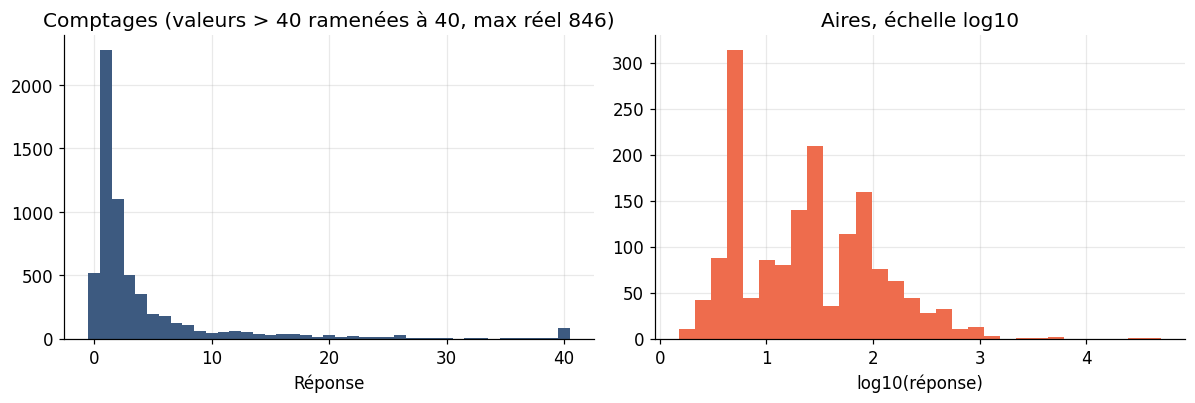


Réponses texte :


,count,min,median,max
source,,,,
ifc_bench,249,25,197.0,3977
opening_design,16,2,26.0,68



Exemple court :
On sheet A-801 of the Xcel Sports Complex drawings, which hardware group is specified for door 107.A?
19

Début d'une réponse longue :
What materials are used in the walls?
Total Unique Materials: 17
   Wall Types with Material Data: 39

   Complete Wall Type Material Compositions:
   Betongvegg 200:
     - Betong bærende: 201mm

   AV02T:
     - Gips: 13mm
     - Stålbindv.: 100mm
     Total thickness: 113mm

   AV03T:
     - Gips: 13mm
     - Stålbindv.: 100mm
     Total thickness: 113mm

   AV52T:
     - Gips: 11mm
     - Bindingsverk: 122mm
     - Sløyfer: 25mm
     - Platekledning: 10mm
     - Stålbindv.: 99mm
     - Krysslekting: 30mm
     - Gips protect: 13mm
     - Isolasjon : 50mm
     - cut stone: 150mm
     - Puss: 15mm
     - Kryssfiner: 15mm
     Total thickness: 540mm

   AV50T:
     - Gips: 11mm
     - Bindingsverk: 148mm
     - Isolasjon : 50mm
 ...


In [12]:
num = questions[questions["answer"].map(lambda v: isinstance(v, (int, float)) and not isinstance(v, bool))].copy()
num["answer"] = num["answer"].astype(float)

summary = (
    num.groupby("type")["answer"]
    .agg(n="size", min="min", median="median", mean="mean", p90=lambda s: s.quantile(0.9), max="max")
    .round(2)
)
display(summary)

print("Réponses nulles (comptage = 0) :", int((questions["answer"] == 0).sum()))
print("Aires en ft² :", int((questions["unit"] == "ft2").sum()))
display(questions.loc[questions["unit"] == "ft2", ["source", "question", "answer", "unit", "path"]].head(9))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
counts = num.loc[num["type"] == "count", "answer"]
axes[0].hist(counts.clip(upper=40), bins=np.arange(-0.5, 41.5, 1), color="#3d5a80")
axes[0].set_title(f"Comptages (valeurs > 40 ramenées à 40, max réel {counts.max():.0f})")
axes[0].set_xlabel("Réponse")
areas = num.loc[num["type"] == "area", "answer"]
axes[1].hist(np.log10(areas), bins=30, color="#ee6c4d")
axes[1].set_title("Aires, échelle log10")
axes[1].set_xlabel("log10(réponse)")
plt.tight_layout()
plt.show()

text = questions[questions["type"] == "text"].copy()
text["a_len"] = text["answer"].str.len()
print("\nRéponses texte :")
display(text.groupby("source")["a_len"].agg(["count", "min", "median", "max"]).round(0))
print("\nExemple court :")
short = text.loc[text["a_len"].idxmin()]
print(short["question"])
print(short["answer"][:500])
print("\nDébut d'une réponse longue :")
long = text.loc[text["a_len"].idxmax()]
print(long["question"][:240])
print(str(long["answer"])[:700], "...")

## 8. Deux plans, en détail

Même logique des deux côtés (compter des objets, lire une surface), mais le dessin n'a rien à voir : un plan marketing finlandais d'un côté, un plan d'étage suisse annoté de l'autre. Les questions suisses de surface reprennent des valeurs déjà imprimées sur le plan.


data/cubicasa5k/colorful-11397.png
10 questions, 5 faits


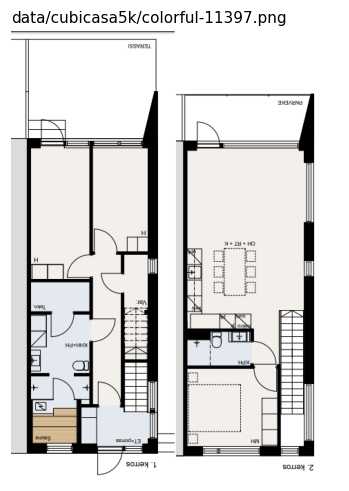

,lang,type,unit,answer,question
0,en,count,count,13,How many windows are shown on this floor plan?
1,en,count,count,2,How many toilet bowls (WC seats) are drawn on ...
2,en,count,count,3,How many sinks and wash basins (kitchen and ba...
3,en,count,count,3,How many showers and bathtubs are drawn on thi...
4,en,count,count,2,How many floors (storeys) does this floor plan...



data/swiss_dwellings/site1000_bldg2082_floor9385.pdf
34 questions, 17 faits


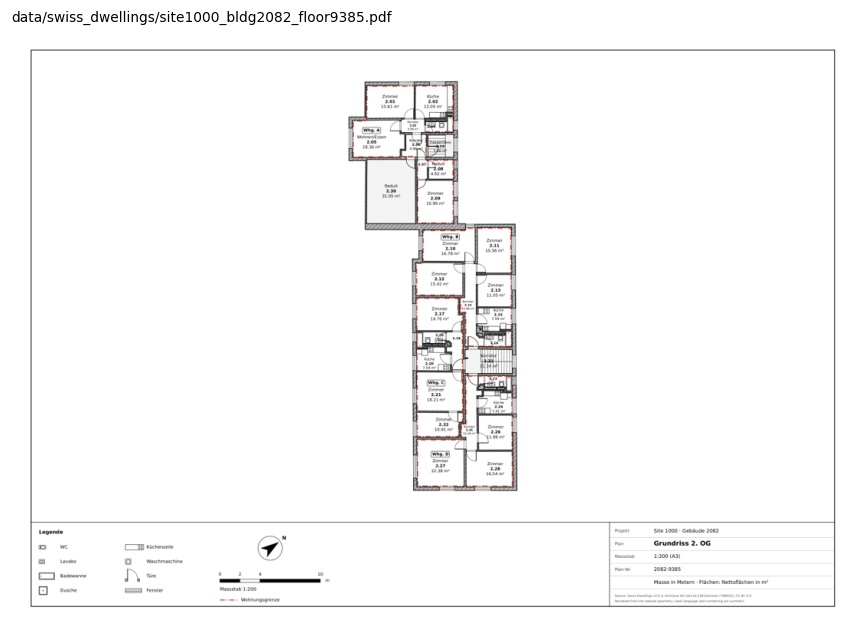

,lang,type,unit,answer,question
0,en,count,count,4,How many apartments (residential units) are sh...
1,en,area,m2,184.93,What is the total net area in m² of all rooms ...
2,en,area,m2,80.34,What is the net floor area of apartment A in m...
3,en,area,m2,80.83,What is the net floor area of apartment B in m...
4,en,area,m2,15.9,What is the net floor area of room 2.09 ('Zimm...
5,en,area,m2,16.78,What is the net floor area of room 2.10 ('Zimm...
6,en,count,count,4,How many bathtubs are drawn on this floor plan?
7,en,count,count,4,How many washbasins are drawn on this floor plan?
8,en,area,m2,341.45,What is the total net floor area in m² of all ...
9,en,count,count,28,How many windows are drawn on this floor plan?


In [13]:
def show_plan(rel, ncols_note=""):
    path = ROOT / rel
    print(f"\n{'=' * 80}\n{rel}")
    qs = questions[questions["path"] == rel].copy()
    if qs.empty:
        # Le PNG suisse n'est pas la cible : on prend le jumeau qui a des questions.
        stem = Path(rel).stem
        qs = questions[questions["path"].str.contains(stem, regex=False)].copy()
        print("(questions rattachées au jumeau", qs["path"].iloc[0] if len(qs) else "?", ")")
    print(f"{len(qs)} questions, {qs['fact_id'].nunique() if len(qs) else 0} faits")
    if rel.lower().endswith((".png", ".jpg", ".jpeg")):
        show_images([(path, rel)], ncols=1, title_size=10)
    elif fitz is not None and rel.lower().endswith(".pdf"):
        doc = fitz.open(path)
        pix = doc[0].get_pixmap(matrix=fitz.Matrix(1.2, 1.2), alpha=False)
        im = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
        doc.close()
        im.thumbnail((1100, 1100))
        fig, ax = plt.subplots(figsize=(8, 8))
        ax.imshow(im)
        ax.set_title(rel, fontsize=9, loc="left")
        ax.axis("off")
        plt.tight_layout()
        plt.show()
    # Une formulation par fait, de préférence en anglais.
    if qs.empty:
        return
    one = (
        qs.assign(_en=qs["lang"].ne("en"))
        .sort_values("_en")
        .groupby("fact_id", sort=False, as_index=False)
        .first()
    )
    view = one[["lang", "type", "unit", "answer", "question"]].reset_index(drop=True)
    display(view)

show_plan("data/cubicasa5k/colorful-11397.png")
show_plan("data/swiss_dwellings/site1000_bldg2082_floor9385.pdf")

## 9. Ce qu'on retient

1. **Ce n'est pas un seul problème de vision.** Cinq sources portent les questions, et elles ne demandent pas la même chose. CubiCasa : compter des symboles sur un plan d'appartement. Swiss Dwellings : compter et lire des surfaces déjà écrites sur le plan. IFC : interroger un modèle BIM (aires, volumes, longueurs, et de longs textes descriptifs). Opening Design : lire une liasse de plans d'exécution (nomenclatures, planches).
2. **Les archives n'ont pas de questions dans ce preview.** Finna, Europeana, HABS et Wikimedia représentent pourtant une grande partie des images, et ce sont les plus hétérogènes (scans historiques, coupes, élévations, documents qui ne sont pas des plans).
3. **7 990 lignes, environ 4 150 questions distinctes.** Presque toutes sont écrites deux fois, en anglais puis dans une autre langue. Évaluer un modèle sur les lignes brutes compte deux fois la même réponse.
4. **Le fichier cité n'est pas toujours l'image la plus simple.** Swiss Dwellings existe en PNG, PDF et DXF ; la question vise le PDF. Les IFC ne sont pas des images : ce sont des fichiers STEP, dont quelques-uns dépassent 50 Mo, et un au moins est presque vide.
5. **Les réponses numériques sont très dissymétriques.** Comptages petits mais avec une queue jusqu'à plusieurs centaines ; aires autour de quelques dizaines de m², plus une poignée de valeurs en ft². Les réponses texte vont d'une ligne à plusieurs milliers de caractères.
6. **Le scoring n'est pas le même selon le type** : exact pour un comptage, tolérance de 2 % pour une mesure, libre pour le texte.

Piste naturelle pour la suite : séparer la tâche « lire un plan raster » (CubiCasa, Swiss Dwellings, planches PDF) de la tâche « interroger un IFC », plutôt que d'entraîner ou de prompter un seul pipeline sur les deux.